# Energy Intelligence AI · Calibração e eventos

Etapa 2 do MVP. A lógica reutilizável está em `src/`; este notebook lê os modelos
e os resultados de `python -m src.train`, sem retreinar na inferência.

**Anomalias:** treino 60%, Validation 20%, Holdout final 20%. O perfil horário e
a escala 0–100 são aprendidos apenas no treino. O threshold é escolhido somente
na Validation; não há refit posterior. Forecasting conserva seu protocolo anterior.
O score é relativo ao detector, **não é probabilidade**.


In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/inference.py').exists())
sys.path.insert(0, str(ROOT)) if str(ROOT) not in sys.path else None
from src.utils import DATASET_PATH, MODEL_DIR, OUTPUT_DIR
from src.data_processing import load_data
from src.inference import EnergyPipeline
from src.anomaly_detection import detect_anomalies, evaluate_anomaly_model
from src.events import build_anomaly_events, summarize_anomaly_events

raw = load_data(DATASET_PATH, require_electrical=True)
pipeline = EnergyPipeline.load(MODEL_DIR)
metrics = json.loads((MODEL_DIR / 'metrics.json').read_text(encoding='utf-8'))
calibration = metrics['anomaly_threshold_calibration']
split = metrics['anomaly_split']
pd.DataFrame([{'período': name, 'início': split[name+'_start'], 'fim': split[name+'_end'],
               'medições': split[name+'_rows']} for name in ['train','validation','holdout']])


,período,início,fim,medições
0,train,2026-01-01T00:00:00,2026-01-18T23:45:00,1728
1,validation,2026-01-19T00:00:00,2026-01-24T23:45:00,576
2,holdout,2026-01-25T00:00:00,2026-01-30T23:45:00,576


## Corte padrão → calibração

O corte padrão corresponde a `decision_function < 0`, expresso na escala
congelada do score. O corte calibrado usa `score >= threshold`. A contaminação
permanece fixa; o threshold persistido passa a controlar a decisão final.

Maximizar F1 mantendo recall ≥ 0,80 na Validation; empates favorecem menos FP
e depois o maior threshold. Ausência de rótulos, de ambas as classes ou de
candidato viável conserva o corte padrão e registra o motivo.


In [2]:
print('Threshold do V2 histórico (treino 80%):', metrics['anomaly_legacy']['default_threshold'])
print('Threshold padrão do detector atual (treino 60%):', calibration['default_threshold'])
print('Threshold selecionado:', calibration['selected_threshold'])
print('Status:', calibration['status'])
threshold_table = pd.read_csv(OUTPUT_DIR / 'anomaly_thresholds.csv')
threshold_table.sort_values(['f1','false_positives','threshold'], ascending=[False,True,False]).head(12)


Threshold do V2 histórico (treino 80%): 57.29997581402037
Threshold padrão do detector atual (treino 60%): 64.66479702893021
Threshold selecionado: 68.0
Status: calibrated


,threshold,evaluated_rows,precision,recall,f1,false_positive_rate,specificity,balanced_accuracy,false_positives,false_negatives,true_positives,true_negatives
68,68.0,576,1.000000,0.833333,0.909091,0.000000,1.000000,0.916667,0,1,5,570
67,67.0,576,1.000000,0.833333,0.909091,0.000000,1.000000,0.916667,0,1,5,570
62,62.0,576,0.750000,1.000000,0.857143,0.003509,0.996491,0.998246,2,0,6,568
61,61.0,576,0.750000,1.000000,0.857143,0.003509,0.996491,0.998246,2,0,6,568
60,60.0,576,0.750000,1.000000,0.857143,0.003509,0.996491,0.998246,2,0,6,568
66,66.0,576,0.833333,0.833333,0.833333,0.001754,0.998246,0.915789,1,1,5,569
75,75.0,576,1.000000,0.666667,0.800000,0.000000,1.000000,0.833333,0,2,4,570
74,74.0,576,1.000000,0.666667,0.800000,0.000000,1.000000,0.833333,0,2,4,570
73,73.0,576,1.000000,0.666667,0.800000,0.000000,1.000000,0.833333,0,2,4,570
72,72.0,576,1.000000,0.666667,0.800000,0.000000,1.000000,0.833333,0,2,4,570


## Curva Precision–Recall · Validation

Esta curva usa exclusivamente os rótulos de validação e os scores do modelo
treinado anteriormente. O demo tem somente seis positivos na Validation e
cinco no Holdout: a visualização é descritiva, sem comprovar generalização.


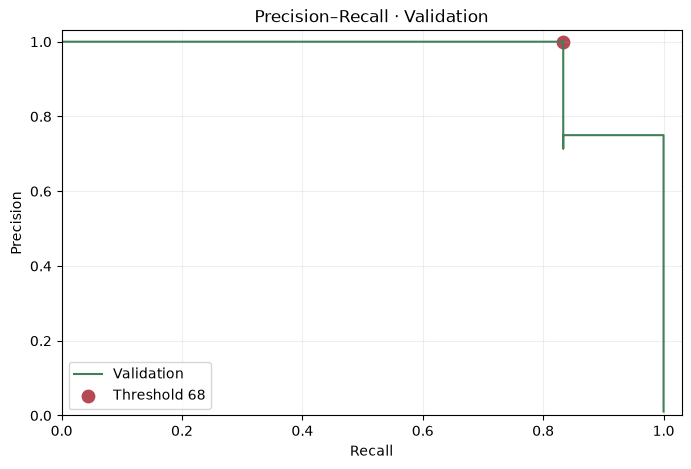

In [3]:
validation = raw.loc[raw.timestamp.between(pd.Timestamp(split['validation_start']), pd.Timestamp(split['validation_end']))]
validation_scores = detect_anomalies(validation, pipeline.anomaly, use_calibrated_threshold=False)
labelled = validation_scores.is_anomaly.notna() if 'is_anomaly' in validation_scores else pd.Series(False, index=validation_scores.index)
if labelled.any() and validation_scores.loc[labelled,'is_anomaly'].nunique() == 2:
    precision, recall, cuts = precision_recall_curve(validation_scores.loc[labelled,'is_anomaly'].astype(int),
                                                    validation_scores.loc[labelled,'anomaly_score'])
    fig, ax = plt.subplots(figsize=(8,5))
    ax.step(recall, precision, where='post', label='Validation', color='#427f57')
    selected = metrics['anomaly_comparison']['validation']['calibrated']
    if calibration['selected_threshold'] is not None:
        ax.scatter(selected['recall'], selected['precision'], color='#b44a54', s=80,
                   label=f"Threshold {calibration['selected_threshold']:g}")
    ax.set(xlabel='Recall', ylabel='Precision', title='Precision–Recall · Validation', xlim=(0,1.03), ylim=(0,1.03))
    ax.grid(alpha=.2); ax.legend(); plt.show()
else:
    print('Classes/labels insuficientes para curva PR.')


## Validation e Holdout: comparações separadas

A referência histórica V2 ajustada em 80% reproduz o estado anterior. O detector
atual é ajustado em 60% para reservar a validação. Comparar corte padrão e corte
calibrado do **mesmo detector de 60%** isola o efeito do threshold.
Os resultados de Holdout são consultados somente depois da seleção.


In [4]:
columns = ['precision','recall','f1','false_positives','false_negatives','true_positives',
           'true_negatives','false_positive_rate','specificity','balanced_accuracy']
comparison = {}
legacy = metrics['anomaly_legacy']['holdout']
if legacy is not None:
    comparison['Holdout · V2 histórico · treino 80%'] = legacy
for period, methods in metrics['anomaly_comparison'].items():
    for name, values in methods.items():
        if values is not None:
            comparison[f'{period.title()} · {name} · treino 60%'] = values
pd.DataFrame(comparison).T[columns].round(4)


,precision,recall,f1,false_positives,false_negatives,true_positives,true_negatives,false_positive_rate,specificity,balanced_accuracy
Holdout · V2 histórico · treino 80%,0.555556,1.0,0.714286,4,0,5,567,0.007005,0.992995,0.996497
Validation · default · treino 60%,0.714286,0.833333,0.769231,2,1,5,568,0.003509,0.996491,0.914912
Validation · calibrated · treino 60%,1.0,0.833333,0.909091,0,1,5,570,0.0,1.0,0.916667
Holdout · default · treino 60%,0.571429,0.8,0.666667,3,1,4,568,0.005254,0.994746,0.897373
Holdout · calibrated · treino 60%,1.0,0.8,0.888889,0,1,4,571,0.0,1.0,0.9


In [5]:
if metrics['anomaly_holdout'] is not None:
    before = metrics['anomaly_legacy']['holdout']
    after = metrics['anomaly_holdout']
    print(f"Referência histórica → calibrado: FP {before['false_positives']} → {after['false_positives']}; FN {before['false_negatives']} → {after['false_negatives']}")
    same_before = metrics['anomaly_comparison']['holdout']['default']
    print(f"Mesmo detector 60%: FP {same_before['false_positives']} → {after['false_positives']}; FN {same_before['false_negatives']} → {after['false_negatives']}")
    print('Matriz calibrada [linhas reais, colunas previstas]:', after['confusion_matrix'])


Referência histórica → calibrado: FP 4 → 0; FN 0 → 1
Mesmo detector 60%: FP 3 → 0; FN 1 → 1
Matriz calibrada [linhas reais, colunas previstas]: [[571, 0], [1, 4]]


## Pontos → eventos operacionais

Pontos anômalos adjacentes com gap ≤15 min formam um evento. Uma medição normal
interrompe o grupo. A tolerância é configurável; não se exige continuidade através
de dados desconhecidos. Pontos isolados ficam `suspected`; dois ou mais pontos
ficam `confirmed`, indicando apenas persistência.

Duração = fim − início (um ponto tem 0 min). Severidade é a maior dos pontos.
Potência esperada é a média das previsões do evento. O maior desvio relativo em
magnitude preserva o sinal; referências próximas de zero não geram percentuais.
Nenhuma mensagem diagnostica causa física. Eventos são agregados do lote fornecido,
sem armazenamento ou acompanhamento contínuo entre chamadas.


In [6]:
analysis = pipeline.analyze(raw)
holdout = analysis.loc[analysis.timestamp.ge(pd.Timestamp(split['holdout_start']))]
policy = metrics['operational_events']['policy']
events = build_anomaly_events(holdout, **policy)
print(summarize_anomaly_events(events))
events


{'total_events': 4, 'confirmed_events': 0, 'suspected_events': 4, 'critical_events': 3, 'total_duration_minutes': 0.0, 'severity_distribution': {'Baixo': 0, 'Moderado': 0, 'Alto': 1, 'Crítico': 3}}


,event_id,start_timestamp,end_timestamp,duration_minutes,number_of_points,max_active_power_kw,mean_active_power_kw,expected_power_kw,max_relative_deviation_pct,max_anomaly_score,mean_anomaly_score,severity,status,message
0,EVT-20260125T034500,2026-01-25 03:45:00,2026-01-25 03:45:00,0.0,1,2.864,2.864,1.0115,183.143846,71.912935,71.912935,Alto,suspected,Evento energético anômalo — severidade Alto. I...
1,EVT-20260126T103000,2026-01-26 10:30:00,2026-01-26 10:30:00,0.0,1,19.034,19.034,6.8900,176.255443,100.000000,100.000000,Crítico,suspected,Evento energético anômalo — severidade Crítico...
2,EVT-20260126T143000,2026-01-26 14:30:00,2026-01-26 14:30:00,0.0,1,21.784,21.784,8.0900,169.270705,100.000000,100.000000,Crítico,suspected,Evento energético anômalo — severidade Crítico...
3,EVT-20260126T194500,2026-01-26 19:45:00,2026-01-26 19:45:00,0.0,1,18.790,18.790,10.2225,83.810223,88.175438,88.175438,Crítico,suspected,Evento energético anômalo — severidade Crítico...


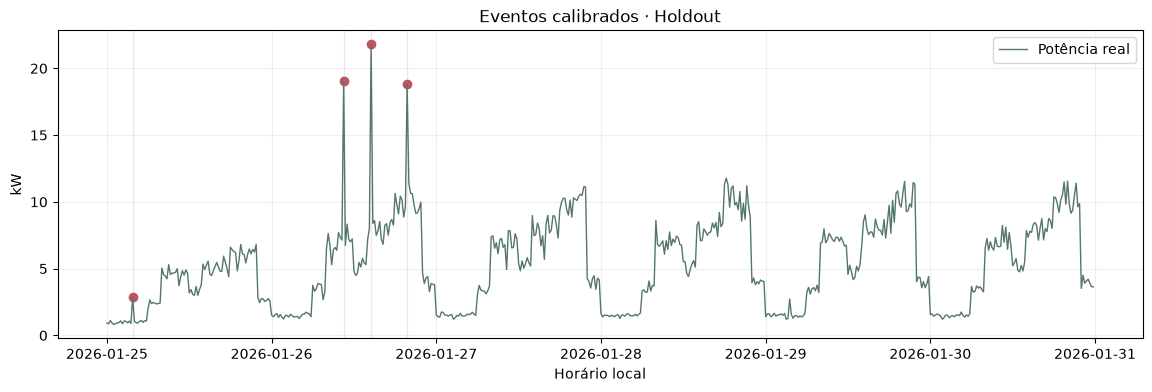

In [7]:
fig, ax = plt.subplots(figsize=(14,4))
ax.plot(holdout.timestamp, holdout.active_power_kw, label='Potência real', linewidth=1, color='#547768')
for event in events.itertuples():
    ax.scatter([event.start_timestamp], [event.max_active_power_kw], color='#bd5663')
    ax.axvspan(event.start_timestamp, event.end_timestamp, color='#bd5663', alpha=.15)
ax.set(title='Eventos calibrados · Holdout', ylabel='kW', xlabel='Horário local')
ax.grid(alpha=.2); ax.legend(); plt.show()


## Exemplo didático de persistência

As linhas abaixo demonstram somente o agrupamento; não entram nas métricas nem
nos arquivos do demo. Um evento com três pontos separados por 15 min dura 30 min.


In [8]:
illustrative = pd.DataFrame({'timestamp': pd.date_range('2026-02-01 18:15', periods=3, freq='15min'),
    'active_power_kw': [18.,19.,18.5], 'expected_power_kw': 9., 'is_anomaly_prediction': 1,
    'anomaly_score': [81.,91.,86.], 'severity': ['Crítico']*3})
illustrative_events = build_anomaly_events(illustrative, **policy)
assert illustrative_events.iloc[0].duration_minutes == 30
assert illustrative_events.iloc[0].status == 'confirmed'
illustrative_events


,event_id,start_timestamp,end_timestamp,duration_minutes,number_of_points,max_active_power_kw,mean_active_power_kw,expected_power_kw,max_relative_deviation_pct,max_anomaly_score,mean_anomaly_score,severity,status,message
0,EVT-20260201T181500,2026-02-01 18:15:00,2026-02-01 18:45:00,30.0,3,19.0,18.5,9.0,111.111111,91.0,86.0,Crítico,confirmed,Evento energético anômalo — severidade Crítico...


## Execução e limitações

```powershell
.\.venv\Scripts\python.exe -m src.train
.\.venv\Scripts\python.exe -m pytest -q
.\.venv\Scripts\python.exe -m uvicorn app.api:app --reload
.\.venv\Scripts\python.exe -m streamlit run app/dashboard.py
```

`POST /analyze/events` retorna resumo e eventos; `/analyze` mantém análise por
linha. A aba Eventos permite ajustar persistência/gap e exportar CSV agregado.
Uma linha por evento fica em `anomaly_events.csv`; pontos ficam em
`anomaly_points.csv`; a grade de validação fica em `anomaly_thresholds.csv`.

O threshold foi escolhido sem consultar Holdout. Os resultados do demo são
sensíveis à pequena quantidade de eventos e à divisão temporal; reduzir FP pode
aumentar FN. Validar em mais meses/instalações antes de alterar políticas operacionais.
